In [2]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import warnings 
warnings.filterwarnings('ignore')

x_train = np.load('../models/x_train.npy')
x_test = np.load('../models/x_test.npy')
y_train = np.load('../models/y_train.npy')
y_test = np.load('../models/y_test.npy')

with open('../models/best_model.pkl', 'rb') as f:
    model = pickle.load(f)

with open('../models/feature_names.pkl', 'rb') as f:
    feature_names = pickle.load(f)

with open('../models/feature_pipeline.pkl', 'rb') as f:
    pipeline = pickle.load(f)

selector = pipeline.named_steps['selector']
selected_mask = selector.get_support()
selected_features = [feature_names[i] for i in range(len(feature_names)) if selected_mask[i]]
print(f'Selected features: {selected_features}')

Selected features: ['url_length', 'hostname_length', 'nb_dots', 'nb_hyphens', 'nb_slash', 'nb_at', 'nb_qmark', 'nb_equal', 'nb_underscore', 'nb_percent', 'nb_digits', 'ratio_digits_url', 'ratio_digits_host', 'https_token', 'ip_in_hostname', 'nb_subdomains', 'prefix_suffix', 'suspicious_tld', 'phishing_hints', 'brand_similarity', 'path_length', 'has_port', 'double_slash_in_path', 'nb_hyperlinks', 'ratio_internal_links', 'nb_external_css', 'has_login_form', 'has_iframe', 'external_favicon', 'title_matches_domain']


In [4]:
y_pred = model.predict(x_test)

print('CLASSIFICATION REPORT')
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Phishing']))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.97      0.99      0.98      3000
    Phishing       0.99      0.97      0.98      3000

    accuracy                           0.98      6000
   macro avg       0.98      0.98      0.98      6000
weighted avg       0.98      0.98      0.98      6000



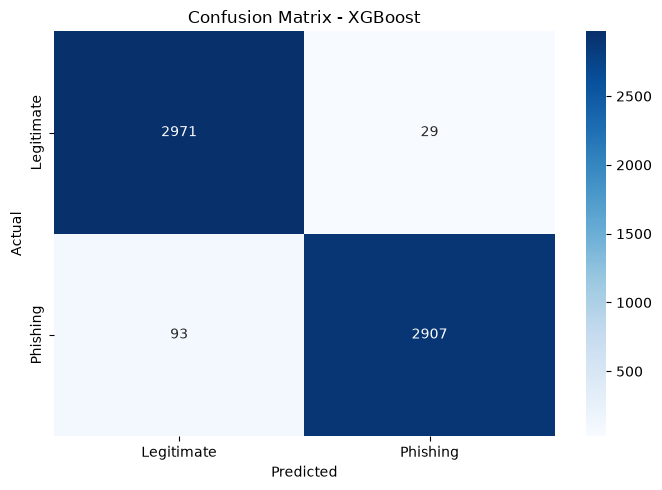

true negative (legit correctly identified): 2971
False positive (legit wrongly flagged): 29
False negative (phishing missed): 93
true positive (phishing correctly caught): 2907


In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate', 'Phishing'],
            yticklabels=['Legitimate', 'Phishing'])

plt.title('Confusion Matrix - XGBoost')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('../results/confusion_matrix.png', dpi=200)
plt.show()

tn, fp, fn, tp = cm.ravel()

print(f'true negative (legit correctly identified): {tn}')
print(f'False positive (legit wrongly flagged): {fp}')
print(f'False negative (phishing missed): {fn}')
print(f'true positive (phishing correctly caught): {tp}')


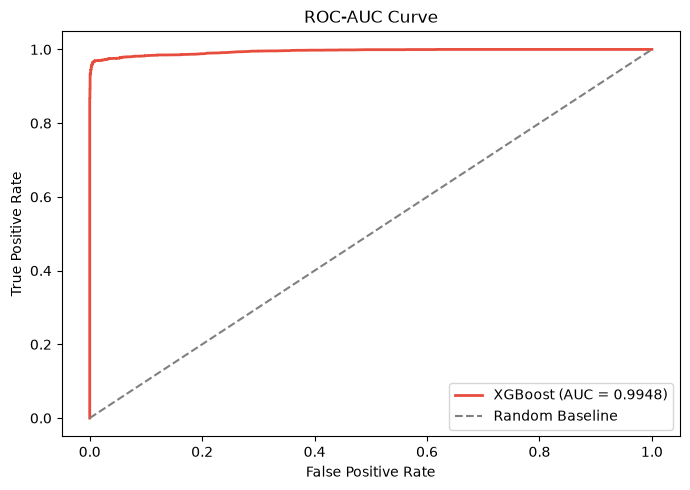

ROC-AUC Score: 0.9948


In [7]:
y_prob = model.predict_proba(x_test)[:,1]
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#e74c3c', lw=2, label=f'XGBoost (AUC = {auc:.4f})')
plt.plot([0,1], [0, 1], color='grey', linestyle='--', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve')
plt.legend()
plt.tight_layout()
plt.savefig('../results/roc_curve.png', dpi=200)
plt.show()
print(f'ROC-AUC Score: {auc:.4f}')

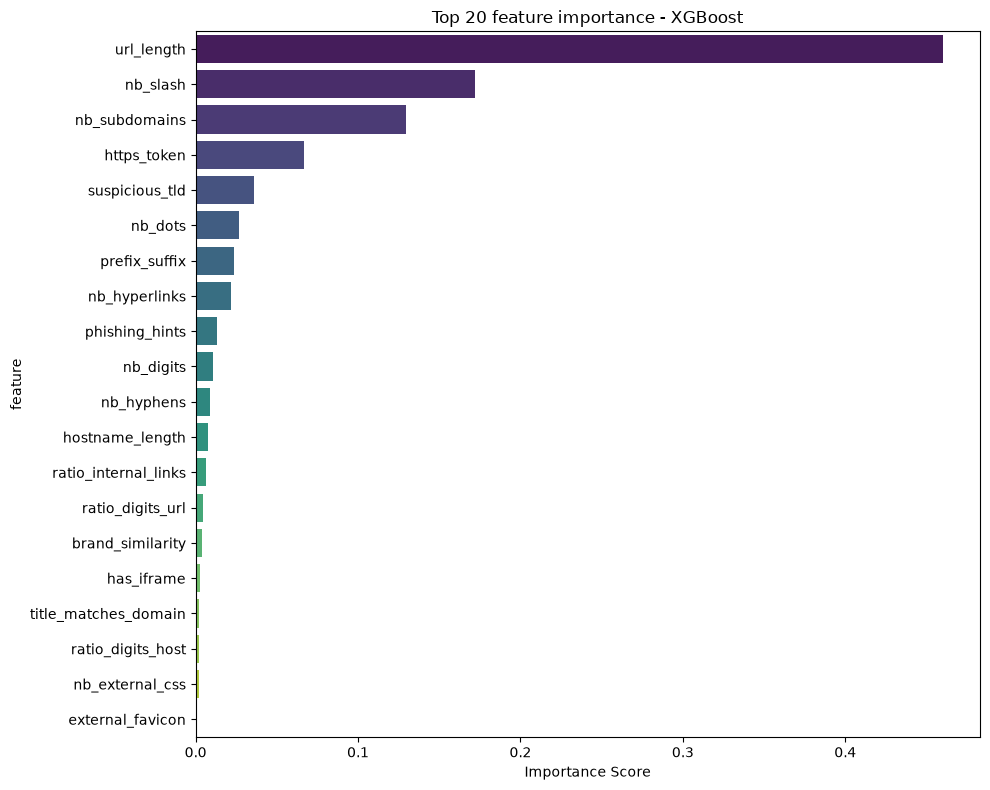

                 feature  importance
0             url_length    0.459956
4               nb_slash    0.172313
15         nb_subdomains    0.129731
13           https_token    0.066466
17        suspicious_tld    0.035850
2                nb_dots    0.026428
16         prefix_suffix    0.023348
23         nb_hyperlinks    0.021647
18        phishing_hints    0.013053
10             nb_digits    0.010401
3             nb_hyphens    0.008859
1        hostname_length    0.007417
24  ratio_internal_links    0.006238
11      ratio_digits_url    0.004839
19      brand_similarity    0.003986
27            has_iframe    0.002601
29  title_matches_domain    0.002072
12     ratio_digits_host    0.001989
25       nb_external_css    0.001857
28      external_favicon    0.000948


In [9]:
importances = model.feature_importances_
feat_imp_df = pd.DataFrame({
    "feature" : selected_features,
    "importance": importances
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='importance', y='feature', data=feat_imp_df.head(20), palette='viridis')
plt.title('Top 20 feature importance - XGBoost')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.savefig('../results/feature_importance.png', dpi=200)
plt.show()

print(feat_imp_df.head(20))

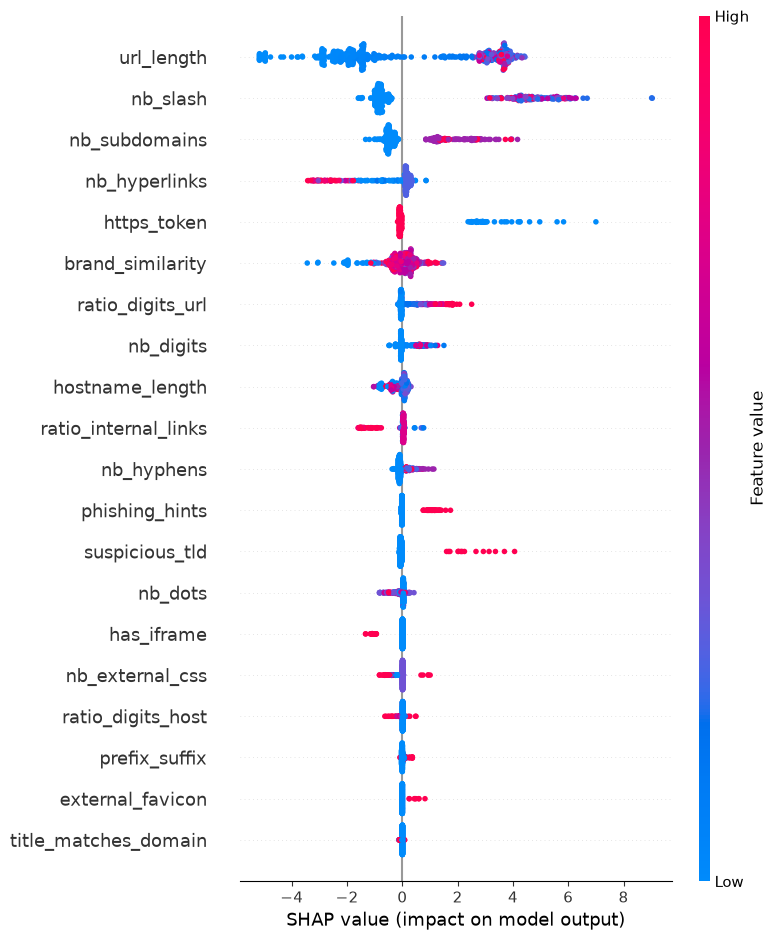

Shap summary saved


In [11]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(x_test[:500])

plt.figure()
shap.summary_plot(shap_values, x_test[:500],
                  feature_names=selected_features,
                  show=False)
plt.tight_layout()
plt.savefig('../results/shap_summary.png', dpi=200, bbox_inches='tight') 
plt.show()
print('Shap summary saved')                 

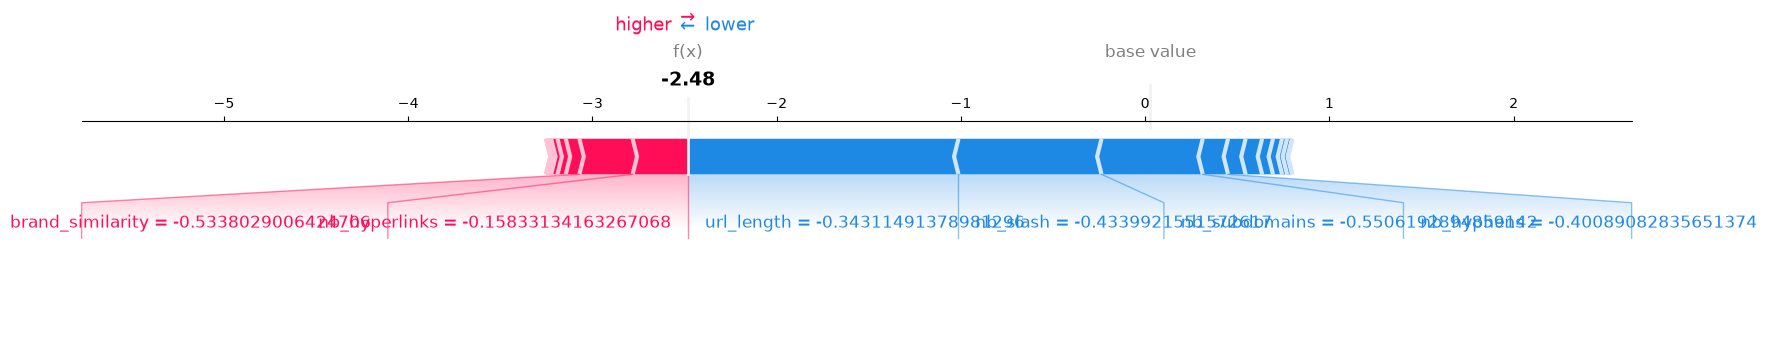

Prediction: Legitimate
Actual: Legitimate


In [15]:
idx = 0
shap.initjs()

force_plot = shap.force_plot(
    explainer.expected_value,
    shap_values[idx],
    x_test[idx],
    feature_names=selected_features,
    matplotlib=True,
    show=False
)
plt.savefig('../results/shap_force_plot.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'Prediction: {'Phishing' if y_pred[idx] == 1 else 'Legitimate'}')
print(f'Actual: {'Phishing' if y_pred[idx] == 1 else 'Legitimate'}')